## Plotting maps in ARTop

Maps in ARTop are based on the SunPy maps class (see https://sunpy.org/ for many more details) and make use of standard Matplotlib commands. Here, we present some examples of how to create some basic, but useful, maps.

The variables that can be mapped in ARTop are:

```
bz         :  z-component of mag. field (Gauss)
vz         :  z-component of vel. field (km/s)
sz         :  z-component of Poynting flux (Gauss^2km/s)
windCur    :  current-carrying part of field line winding rate (km^2/s)
helCur     :  current-carrying part of field line helicity rate (Gauss^2km^2/s)
windPot    :  potential part of field line winding rate (km^2/s)
helPot     :  potential part of field line helicity rate (Gauss^2km^2/s)
windBraid  :  braiding component of field line winding rate (km^2/s)
helBraid   :  braiding component of field line helicity rate (Gauss^2km^2/s)
wind       :  total field line winding rate (km^2/s)
hel        :  total field line helicity rate (Gauss^2km^2/s)
deltaL     :  field line delta winding rate (km^2/s)
deltaH     :  field line delta helicity rate (Gauss^2km^2/s)
```


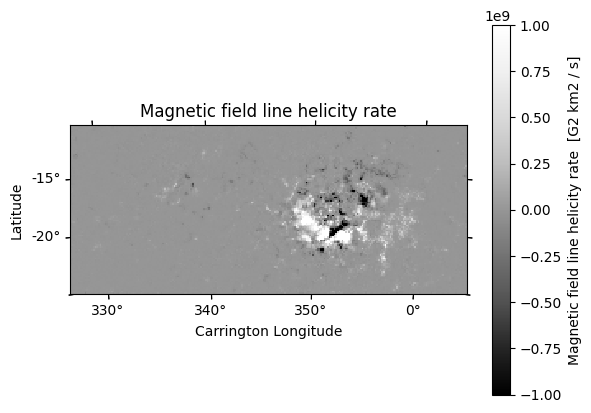

In [ ]:
# Example 1: Plot a basic map

import os
import sys
cwd = os.getcwd()
sys.path.insert(1, os.path.join(cwd,'source','python'))    # If your version of analysis.py is in another location, change this path.
from analysis import *

# Get the data.
outputDir = 'E:/Research/Work/202405_solar_storm/helicity/run_3/Output/'                     # Set the output directory (containing the Data folder and *.txt).
fileNum = 10                                               # Number of the output file in the Data folder. 
varKey = 'hel'                                             # The variable to be mapped.
map1 = readMap(outputDir,fileNum,varKey)                   # Create a SunPy map of the chosen variable.

# Plot the data.
norm = map1.plot_settings['norm']
norm.vmin = -1e9                                                                 # Minimum value.     
norm.vmax = 1e9                                                                  # Maximum value.
# If you don't wish to set minimum and maximum limits, just remove the above
# two lines and the file min. and max. will be selected.

map1.plot(norm=norm,cmap='Greys_r',title='Magnetic field line helicity rate')    # Plot the map with a chosen colour scheme and a title.
plt.grid(alpha=0)                                                                # Turn off the coordinate grid.
cbar = plt.colorbar(label=f"Magnetic field line helicity rate  [{map1.unit}]")   # Add a colourbar showing the variable units.
plt.rcParams['figure.figsize'] = [15, 4]
plt.show()                                                                       # Display the plot.

# Note: if you wish to display the map with a different set of units, you can rescale map1 and enter the units manually in the colourbar label.


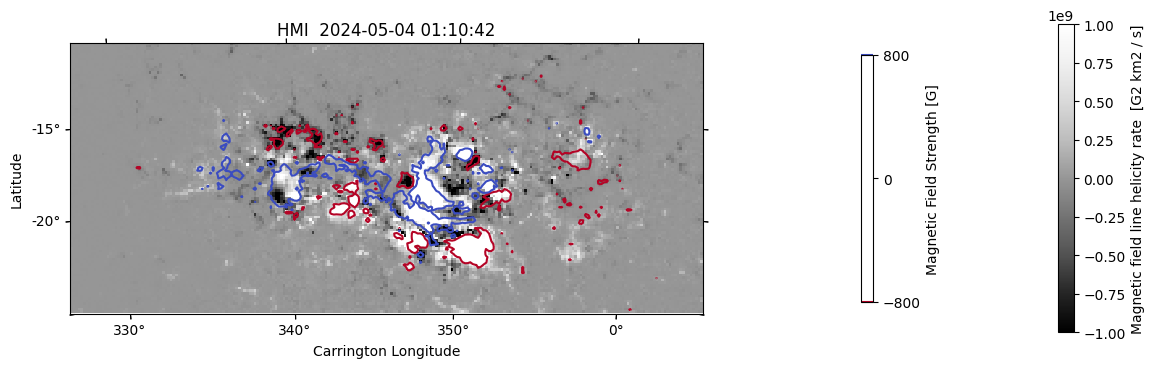

In [4]:
# Example 2: Overplot contours on a map

import os
import sys
cwd = os.getcwd()
sys.path.insert(1, os.path.join(cwd,'source','python'))    # If your version of analysis.py is in another location, change this path.
from analysis import *

# Get the data.
outputDir = 'E:/Research/Work/202405_solar_storm/helicity/run_3/Output/'                 # Set the output directory (containing the Data folder and *.txt).
fileNum = 700                                           # Number of the output file in the Data folder. 
mapVar = 'hel'                                         # The variable to be mapped.
contourVar = 'bz'                                      # The variable to be contoured.
map2 = readMap(outputDir,fileNum,mapVar)               # Create a map of the chosen variable.
mapCont = readMap(outputDir,fileNum,contourVar)        # Create a map of the variable to be contoured.
levels = [800] * mapCont.unit                          # Define the levels for the contour plot (choose only positive levels here).
levels = np.concatenate((-1 * levels[::-1], levels))   # Create negative contours to match the positive ones above.

# Plot the data.
fig = plt.figure()                                                                  # Set up the plot for a map overlayed by contours.
ax = fig.add_subplot(projection=map2)
norm = map2.plot_settings['norm']
norm.vmin = -1e9                                                                    # Minimum value.     
norm.vmax = 1e9                                                                     # Maximum value.
# If you don't wish to set minimum and maximum limits, just remove the above
# two lines and the file min. and max. will be selected.

map2.plot(norm=norm,cmap='Greys_r')                                                 # Plot the map.
plt.grid(alpha=0)                                                                   # Turn off the coordinate grid.
cbar = plt.colorbar(label=f"Magnetic field line helicity rate  [{map2.unit}]")      # Add a colourbar for the mapped variable.                                  

cset = mapCont.draw_contours(levels,axes=ax,cmap='coolwarm_r',alpha=1)              # Create the contours to overlay on the map.
plt.colorbar(cset,                                                                  # Overplot the contours.
             label=f"Magnetic Field Strength [{mapCont.unit}]",
             ticks=list(levels.value) + [0],
             shrink=0.8,
             pad=0.17)


plt.rcParams['figure.figsize'] = [15, 4]
plt.show()                                                                          # Display the plot.